# Исследование Советского городского поселения с BlocksNet

Территория: МО «Советское городское поселение», Выборгский район, Ленинградская область, Россия. Анализ охватывает территорию муниципального образования, а не только пгт Советский. Ноутбук подготовлен по `examples/pipeline.ipynb` из BlocksNet `1.0.0.a9`. Он содержит получение данных и расчёты, но ничего не запускает автоматически.

В официальном хранилище BlocksNet нет готового графа для этой территории. Для эксперимента используется пешеходный граф `walk` из OpenStreetMap через IduEdu `0.4.1`; он запрашивается только при ручном запуске соответствующей ячейки и сохраняется в отдельной папке данных. Это не интермодальный граф.

Источники: [пример pipeline](https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/examples/pipeline.ipynb), [репозиторий BlocksNet-data](https://github.com/IDUclub/blocksnet-data), [документация IduEdu](https://iduclub.github.io/IduEdu/). Данные OpenStreetMap доступны по лицензии ODbL.

## 1. Подготовка Windows

Текущий Python VS Code — 3.14, а закреплённый BlocksNet зависит от IduEdu `0.4.1`, которому нужен Python `3.10–3.12`. Создайте отдельное окружение с Python 3.12. В PowerShell из корня проекта выполните команды по очереди.

Сначала убедитесь, что Python 3.12 установлен: `py --list`. Если версии 3.12 нет, установите Python 3.12 с python.org, затем перезапустите VS Code.

```powershell
py -3.12 -m venv .venv-blocksnet
.\.venv-blocksnet\Scripts\python.exe -m pip install --upgrade pip
.\.venv-blocksnet\Scripts\python.exe -m pip install -e ".[dev]"
.\.venv-blocksnet\Scripts\python.exe -m pip install "blocksnet[ipynb]==1.0.0a9"
.\.venv-blocksnet\Scripts\python.exe -m ipykernel install --user --name blocksnet-1-0-0a9 --display-name "Python 3.12 (BlocksNet 1.0.0a9)"
```

`.[dev]` использует зависимости notebook из существующего `pyproject.toml`; устанавливать пакеты в это окружение сейчас не нужно. Затем откройте notebook и выберите ядро `Python 3.12 (BlocksNet 1.0.0a9)`.

In [2]:
import sys
from importlib.metadata import version
from importlib.metadata import PackageNotFoundError

print("Python:", sys.version.split()[0])
try:
    blocksnet_version = version("blocksnet")
except PackageNotFoundError as exc:
    raise RuntimeError(
        f"BlocksNet не установлен в текущем ядре: {sys.executable}\n"
        'Выберите ядро "Python 3.12 (BlocksNet 1.0.0a9)" в VS Code.'
    ) from exc

print("BlocksNet:", blocksnet_version)
print("IduEdu:", version("iduedu"))

assert (3, 10) <= sys.version_info[:2] < (3, 13), "Для IduEdu 0.4.1 нужен Python 3.10-3.12. Выберите правильное ядро."
assert version("blocksnet") == "1.0.0a9", "Нужен BlocksNet 1.0.0.a9. Проверьте выбранное ядро."
assert version("iduedu") == "0.4.1", "Проверьте версию IduEdu, установленную вместе с BlocksNet."

Python: 3.12.0
BlocksNet: 1.0.0a9
IduEdu: 0.4.1


## 2. Как работать с notebook

Выполняйте ячейки сверху вниз кнопкой запуска текущей ячейки. **Не используйте «Run All»**: в конце подготовки кварталов есть намеренная остановка. После неё расчётный этап закрыт переключателем `RUN_ANALYSIS = False`; до обсуждения метрик оставьте его выключенным.

Ячейки проверяют наличие готовых GeoJSON и графа и читают их, если файлы уже сохранены. Загрузки из OpenStreetMap происходят только при ручном запуске ячеек, когда соответствующего файла ещё нет.

In [3]:
from enum import Enum
from pathlib import Path

import geopandas as gpd
import networkx as nx
import osmnx as ox
import pandas as pd
import shapely

from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.analysis.provision import competitive_provision
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix, get_accessibility_graph

c:\Users\User\ai-course\python-package-boilerplate\.venv-blocksnet\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
PLACE_QUERY = "Советский, Выборгский район, Ленинградская область, Россия"
DATA_DIR = Path("data") / "sovetsky"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BOUNDARY_FILE = DATA_DIR / "boundary.geojson"
BLOCKS_FILE = DATA_DIR / "blocks.geojson"
GRAPH_FILE = DATA_DIR / "sovetsky_walk.graphml"
MATRIX_FILE = DATA_DIR / "accessibility_walk_minutes.csv"
FOREST_FUND_FILE = DATA_DIR / "forest_fund.geojson"


def save_geojson(layer, path):
    export_layer = layer.copy()
    for column in export_layer.select_dtypes(include=["object"]).columns:
        export_layer[column] = export_layer[column].map(
            lambda value: value.value if isinstance(value, Enum) else value
        )
    export_layer.to_crs(4326).to_file(path, driver="GeoJSON", index=True)


def load_or_fetch_geojson(path, fetch_function, target_crs):
    if path.exists():
        print(f"Читаю готовый файл: {path}")
        return gpd.read_file(path).to_crs(target_crs)
    print(f"Файл {path} не найден; данные будут запрошены при выполнении этой ячейки.")
    layer = fetch_function().reset_index(drop=True)
    save_geojson(layer, path)
    return layer.to_crs(target_crs)

## 3. Границы и кварталообразующие данные

Границы ищутся по названию через OpenStreetMap Nominatim. Для расчёта площадей используется местная метрическая проекция UTM. Слои сохраняются в GeoJSON; при следующем запуске будут прочитаны с диска.

In [6]:
if BOUNDARY_FILE.exists():
    boundaries_wgs84 = gpd.read_file(BOUNDARY_FILE).to_crs(4326)
else:
    boundaries_wgs84 = ox.geocode_to_gdf(PLACE_QUERY).iloc[[0]].copy()
    save_geojson(boundaries_wgs84, BOUNDARY_FILE)

analysis_crs = boundaries_wgs84.estimate_utm_crs()
boundaries = boundaries_wgs84.to_crs(analysis_crs)
print("Проекция для измерений:", analysis_crs)
display(boundaries[["geometry"]])

Проекция для измерений: EPSG:32635


,geometry
0,"MULTIPOLYGON (((603848.309 6719579.567, 603879..."


Для нарезки BlocksNet нужны линии улиц и железных дорог, полигоны/линии воды и внешняя граница. Эта ячейка проверяет каждый GeoJSON отдельно, поэтому уже загруженный слой повторно не запрашивается.

In [7]:
bc_tags = {
    "roads": {"highway": ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified", "living_street", "pedestrian", "service", "track", "road"]},
    "railways": {"railway": ["rail", "light_rail", "subway", "tram"]},
    "water": {"natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"], "landuse": "basin", "water": ["lake", "reservoir"]},
}
boundary_polygon = boundaries_wgs84.geometry.union_all()

water = load_or_fetch_geojson(
    DATA_DIR / "water.geojson",
    lambda: ox.features_from_polygon(boundary_polygon, bc_tags["water"]),
    analysis_crs,
).loc[lambda data: data.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].copy()
roads = load_or_fetch_geojson(
    DATA_DIR / "roads.geojson",
    lambda: ox.features_from_polygon(boundary_polygon, bc_tags["roads"]),
    analysis_crs,
).loc[lambda data: data.geom_type.isin(["LineString", "MultiLineString"])].copy()

RAILWAYS_FILE = DATA_DIR / "railways.geojson"
FETCH_RAILWAYS_FROM_OSM = False

if RAILWAYS_FILE.exists():
    railways = gpd.read_file(RAILWAYS_FILE).to_crs(analysis_crs)
    print("Читаю сохранённые железные дороги:", RAILWAYS_FILE)
elif FETCH_RAILWAYS_FROM_OSM:
    from osmnx._errors import InsufficientResponseError

    try:
        railways = ox.features_from_polygon(boundary_polygon, bc_tags["railways"]).reset_index(drop=True)
    except InsufficientResponseError:
        print("Железные дороги в OSM не найдены; использую пустой слой.")
        railways = gpd.GeoDataFrame(
            geometry=gpd.GeoSeries([], crs=analysis_crs),
            crs=analysis_crs,
        )
    else:
        if railways.empty:
            print("Железные дороги в OSM не найдены; использую пустой слой.")
            railways = gpd.GeoDataFrame(
                geometry=gpd.GeoSeries([], crs="EPSG:4326"),
                crs="EPSG:4326",
            )
        else:
            save_geojson(railways, RAILWAYS_FILE)
        railways = railways.to_crs(analysis_crs)
else:
    print("Запрос железных дорог отключён; использую пустой слой.")
    railways = gpd.GeoDataFrame(
        geometry=gpd.GeoSeries([], crs=analysis_crs),
        crs=analysis_crs,
    )

railways = railways.loc[
    railways.geom_type.isin(["LineString", "MultiLineString"])
].copy()

print("Объектов воды:", len(water))
print("Дорожных линий:", len(roads))
print("Железнодорожных линий:", len(railways))

Читаю готовый файл: data\sovetsky\water.geojson
Читаю готовый файл: data\sovetsky\roads.geojson
Читаю сохранённые железные дороги: data\sovetsky\railways.geojson
Объектов воды: 630
Дорожных линий: 2358
Железнодорожных линий: 120


## 4. Подготовка кварталов

BlocksNet приводит линейные и полигональные объекты к нужным схемам, затем разрезает территорию по уличной сети и исключает водные/неподходящие участки. Результат сохраняется как `blocks.geojson`. Если файл уже есть, пропустите обработку и загрузите его из файла.

Число кварталов: 814


,geometry
block_id,
0,"POLYGON ((592695.084 6713746.638, 592709.539 6..."
1,"POLYGON ((592709.539 6713806.834, 592695.084 6..."
2,"POLYGON ((594795.349 6705367.276, 594820.227 6..."
3,"POLYGON ((594820.227 6705363.121, 594795.349 6..."
4,"POLYGON ((594820.227 6705363.121, 594834.823 6..."


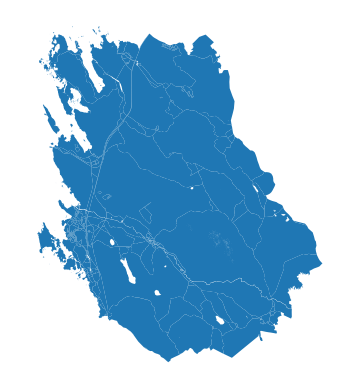

In [8]:
if BLOCKS_FILE.exists():
    blocks = gpd.read_file(BLOCKS_FILE).to_crs(analysis_crs)
    if "block_id" in blocks.columns:
        blocks = blocks.set_index("block_id")
else:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons).reset_index(drop=True)
    blocks.index.name = "block_id"
    save_geojson(blocks, BLOCKS_FILE)

blocks.index.name = "block_id"
print("Число кварталов:", len(blocks))
display(blocks.head())
blocks.plot().set_axis_off()

## СТОП: проверьте кварталы и обсудите метрики

На этом закончена подготовка геометрии. Посмотрите карту и число кварталов. **Не запускайте расчётный раздел, пока не обсудите со мной доступные метрики.** В pipeline предусмотрены: функциональное использование, параметры зданий и население, вместимость школ, матрица времени доступности, конкурентная обеспеченность школ, показатели Spacematrix (`FSI`, `GSI`, `MXI`, `L`, `OSR` и доли площадей), морфотипы Spacematrix и Стрелки, взвешенная площадью доступность.

Расчётный раздел дополнительно закрыт переменной `RUN_ANALYSIS = False`. После нашего согласования переключите её в `True`.

## Какие метрики есть в BlocksNet?

### Простыми словами

BlocksNet описывает город по кварталам: какие функции занимают территорию, сколько в ней зданий и жителей, сколько времени занимает путь между кварталами, хватает ли вместимости школ, какова плотность застройки и к какому типу она относится. Это не один универсальный «балл города», а набор показателей для разных вопросов.

### Все показатели и выходы из `examples/pipeline.ipynb`

#### 1. Функции квартала

- `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` — доля площади квартала, перекрытая объектами соответствующей функции. Единица: доля от 0 до 1; например, `0.25` соответствует 25% площади. Сумма может быть меньше 1, если часть квартала не описана данными.
- `land_use` — преобладающая функция квартала, категория без единиц измерения.
- `share` — доля преобладающей функции, безразмерная величина.

Эти поля помогают увидеть жилые, деловые, промышленные и смешанные части выбранной территории, а также пробелы в исходных данных.

#### 2. Здания и население

- `is_living` — признак жилого здания, `True`/`False`.
- `number_of_floors` — число этажей, этажи.
- `footprint_area` — площадь пятна здания, м².
- `build_floor_area` — суммарная площадь этажей, м².
- `living_area` и `non_living_area` — оценённые жилые и нежилые площади, м².
- `population` — оценка числа жителей, человек. Это расчётная оценка BlocksNet по имеющимся данным, а не перепись населения.
- `objects_count` в агрегированном слое зданий — число зданий в квартале, шт.

Показатели покажут, где сосредоточены жильё и расчётное население, насколько полны сведения о зданиях и как распределены площади.

#### 3. Школы и конкурентная обеспеченность

- `capacity` — вместимость школ/детских садов, мест; `objects_count` — число учреждений в квартале, шт.
- `demand` — расчётная потребность в школьных местах, человеко-места. Она оценивается по населению и нормативу BlocksNet на 1000 жителей.
- `demand_left`, `demand_within`, `demand_without` — неудовлетворённая потребность, обслуженная в пределах порога времени и обслуженная за его пределами; человеко-места.
- `capacity_left`, `capacity_within`, `capacity_without` — свободная вместимость, использованная в пределах порога и использованная за его пределами; человеко-места.
- `provision_strong` — доля потребности, обслуженная в пределах заданного времени, от 0 до 1.
- `provision_weak` — доля потребности, обслуженная в пределах времени или за его пределами в рамках поиска, от 0 до 1.
- `links_df`: `source` и `target` — кварталы спроса и школы, `value` — распределённый между ними спрос, человеко-места.

Это помогает найти кварталы, где не хватает школьных мест или где путь до школы превышает выбранный порог. Порог и норматив берутся из `service_types_config["school"]`. Для детских садов используются отдельные настройки `service_types_config["kindergarten"]`.

**Важно о качестве данных.** OSM обычно показывает объект учреждения, но не гарантирует его проектную вместимость, фактическое число мест или число воспитанников/учащихся. В текущем `buildings.geojson` сохранены расчётные площади и население, но отсутствуют исходные теги типа `building`; поэтому по нему нельзя надёжно отличить жильё от школы или детского сада. Школы и сады должны быть отдельными слоями. Не считайте автоматически подставленную BlocksNet вместимость фактической: для этого pipeline отсутствующее или некорректное `capacity` по умолчанию приводит к ясной ошибке.

**Как подготовить ручной GeoJSON.** Сохраните два файла в `data/sovetsky/`: `schools.geojson` и `kindergartens.geojson`. Каждая строка/feature — одно учреждение; обязательны корректная геометрия (точка входа либо контур здания), объявленная CRS (для GeoJSON обычно EPSG:4326) и поле `capacity` с положительным числом мест. Рекомендуются `name`, `address`, `capacity_source` (например, официальная карточка/ответ администрации) и `capacity_year`. Для расчёта фактической загруженности дополнительно укажите `enrollment` — число учащихся/воспитанников на тот же год; без него загруженность посчитать нельзя. Геометрию точек/полигонов разместите в пределах анализируемой территории и проверьте её по карте. `capacity` — проектные/фактически доступные места, а не число учеников сейчас. Если достоверная вместимость не найдена, не придумывайте её: оставьте пустой и запишите источник/статус, а обеспеченность и загрузку не интерпретируйте как точные. OSM-выгрузка подходит для поиска и геометрии, но вместимость и число учащихся/воспитанников следует дополнить по официальным реестрам/сайтам учреждений или запросу в местный орган управления образованием.

**Демографические данные для сценариев.** Пространственная граница этого исследования — всё МО «Советское городское поселение»: пгт Советский и девять других населённых пунктов. Администрация указывает площадь МО 33 986 га, в том числе 1 490,04 га земель населённых пунктов, и население 8 829 человек на 01.10.2021. Для сопоставления с текущей моделью используем переданную пользователем оценку 9 604 человека на начало 2025 года для всего МО ([страница Wikiwand](https://www.wikiwand.com/ru/%D0%A1%D0%BE%D0%B2%D0%B5%D1%82%D1%81%D0%BA%D0%BE%D0%B5_%D0%B3%D0%BE%D1%80%D0%BE%D0%B4%D1%81%D0%BA%D0%BE%D0%B5_%D0%BF%D0%BE%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5_(%D0%9B%D0%B5%D0%BD%D0%B8%D0%BD%D0%B3%D1%80%D0%B0%D0%B4%D1%81%D0%BA%D0%B0%D1%8F_%D0%BE%D0%B1%D0%BB%D0%B0%D1%81%D1%82%D1%8C)) со ссылкой на оценки Росстата). Это вторичный источник: первичный источник и точную дату следует проверить перед публикацией. Оценку около 6 911 человек для одного пгт не используем как базу сравнения: она относится к меньшей территории. Площадь кварталов в сохранённом результате около 33 730,8 га — примерно на 255,2 га (0,75%) меньше справочной площади МО; границы и полноту покрытия входных данных следует проверить. Площадь земель населённых пунктов не равна площади застройки: для плотности и морфотипов используются фактические геометрии кварталов и зданий.

**Целевой показатель сети.** В версии BlocksNet `1.0.0a9` конфигурация задаёт норматив спроса `120` школьных мест и `61` место в детских садах на 1000 жителей; пороги доступности — 15 и 7 минут соответственно. Для сравнения всей территории МО сопоставляйте модельную оценку населения, агрегированную по кварталам, с оценкой 9 604 жителя МО на начало 2025 года. Именно агрегированное население кварталов используется в итоговом слое и расчёте спроса; сумма исходных зданий до агрегации может отличаться. В старом сохранённом сценарии использовалась сумма исходных зданий (9 681), тогда как итог по кварталам — 9 595; модельный сценарий исправлен на итог по кварталам. Исторический сценарий администрации — 8 829 жителей на 01.10.2021; значение около 6 911 относится только к пгт и оставлено как отдельный контекст. Потребность округляется вверх до целого места. Для оценки 9 604 человека ориентир составляет 1 153 школьных места и 586 мест в детских садах; эквивалент по минимальным размерам конфигурации (школа — 250 мест, сад — 80 мест) — 5 школ и 8 детских садов. Это ориентир, а не норматив числа зданий. Текущий сохранённый результат — 9 595 человек, на 9 человек (около 0,1%) ниже оценки 9 604. Таблица сценариев сохраняется в `target_education_network.csv`. Одинаковая административная граница — необходимое, но не достаточное условие сопоставимости: проверяйте годы и полноту исходных данных, особенно фактическую вместимость учреждений.

#### 4. Пешеходная доступность

- `acc_mx` — матрица времени пути между центрами кварталов по графу `walk`; минуты. Строки и столбцы — `block_id`.
- `area_accessibility` — среднее время пути до квартала, взвешенное площадью кварталов назначения; минуты. Меньшее значение означает, что квартал в среднем ближе к остальной территории по сети.

Карта выявит районы, связанные с городом хуже или лучше остальных. Это не время до конкретной школы и не расстояние по прямой.

#### 5. Плотность застройки

Перед расчётом используются `site_area` (площадь квартала), `footprint_area` (сумма пятен зданий), `build_floor_area`, `living_area` и `non_living_area`; площади измеряются в м². Землепользование само по себе не входит в формулы этих показателей: лесной квартал без зданий получает `FSI = 0` и `GSI = 0`, а не морфотип жилой застройки.

- `FSI` (`fsi`) = площадь всех этажей / площадь квартала. Безразмерный коэффициент: показывает интенсивность использования земли.
- `GSI` (`gsi`) = площадь пятен зданий / площадь квартала. Безразмерная доля от 0 до 1: показывает, какая часть земли занята зданиями.
- `MXI` (`mxi`) = жилая площадь / площадь всех этажей. Безразмерная доля от 0 до 1. В этой версии это доля жилья, а не общий индекс разнообразия городских функций.
- `L` (`l`) = площадь всех этажей / площадь пятен зданий. Безразмерное отношение, интерпретируемое примерно как среднее число этажей.
- `OSR` (`osr`) = открытая площадь квартала / площадь всех этажей. Безразмерное отношение; выше — больше открытого пространства относительно объёма застройки.
- `share_living`, `share_non_living` — жилая и нежилая площади, делённые на площадь пятен зданий; безразмерные коэффициенты. По формулам версии 1.0.0.a9 это не доли, которые обязаны суммироваться в 1.

Вместе эти показатели описывают плотность, высотность и баланс жилой/нежилой застройки. Для кварталов без зданий `MXI`, `L`, `OSR` и доли площадей не определены; это не нули и не ошибка. Такие кварталы отдельно помечаются как незастроенные, а морфотип для них не применяется. `forest_zone_share` — доля квартала от 0 до 1, пересекающаяся с лесными полигонами из `forest_fund.geojson` либо, если этого файла нет, с функциональными зонами, в названии которых есть «лес».

#### 6. Морфотипы

- `spacematrix_df`: `cluster` — номер группы без единиц; `morphotype` — словесный тип, сформированный по значениям `L`, `FSI` и `MXI`.
- `spacematrix_clusters` — сводка по группам: медианные `L`, `FSI`, `MXI`, интерпретации и название типа.
- `strelka_df.morphotype` — категория типа застройки Стрелки, определённая по `L`, `FSI` и `MXI`.

Это позволит сравнить застроенные кварталы по структуре застройки. Незастроенные территории не участвуют в морфотипах и будут явно обозначены как неприменимые; названия классов — классификация, а не физическая единица измерения.

Для точного выделения земель лесного фонда положите в `data/sovetsky/forest_fund.geojson` полигональный слой соответствующих земель с корректной CRS. Без него применяется только приближённое распознавание функциональных зон по тексту `name`/`full_name`; оно не подтверждает юридическую категорию земель и может быть неполным. В обоих случаях отдельно сохраняется доля пересечения лесного слоя с кварталом.

### Что будет видно на выходе

Pipeline показывает таблицы и карты функций кварталов, населения, вместимости школ, сильной обеспеченности школами, двух классификаций морфотипов и взвешенного времени доступности; также сохраняет итоговые таблицы и связи между кварталами. Выводы ограничены полнотой исходных данных.

**Расчётные ячейки остаются за переключателем `RUN_ANALYSIS = False`. Не включайте его до подготовки входных слоёв и согласования показателей.**

In [1]:
RUN_ANALYSIS = False

## 5. Расчёты после согласования метрик

Все следующие вычисления выполняются только при `RUN_ANALYSIS = True`. OSM-слои функционального использования, зданий и школ тоже загружаются лишь при ручном запуске расчётной ячейки, если соответствующих GeoJSON ещё нет.

### Подготовка функциональных зон

Для пгт Советский не следует считать `landuse` из OpenStreetMap полным или официальным функциональным зонированием. OSM может быть неполным и устаревшим; ошибка `502` означает сбой/перегрузку сервиса, а не подтверждение отсутствия объектов. Для анализа предпочтительны цифровые данные генерального плана, ПЗЗ или муниципальной GIS. Если доступна только карта в PDF/скане, её можно геопривязать в QGIS и оцифровать границы зон. Не нужно вручную размечать каждое здание: оцифровывайте полигоны функциональных зон, насколько позволяет источник.

#### Файл и геометрия

Сохраните подготовленный слой как `data/sovetsky/functional_zones.geojson` относительно папки проекта. Геометрия должна быть полигональной (`Polygon`/`MultiPolygon`), с известной системой координат. В QGIS используйте **Экспорт → Сохранить объекты как… → GeoJSON**; можно сохранить в EPSG:4326. Ноутбук перепроецирует слой в рабочую UTM-систему. Исправьте ошибки геометрии, удалите пустые объекты и проверьте, что слой действительно покрывает Советский.

В таблице атрибутов обязательно создайте текстовое поле `functional_zone`. Исходное поле `Landuse` можно сохранить для аудита, а его значения привести к классам BlocksNet. Поддерживаемые классы: `residential` (жилой), `business` (общественно-деловой), `industrial` (производственный/промышленный), `recreation` (рекреационный/озеленённый), `transport` (транспортный), `special` (специального назначения), `agriculture` (сельскохозяйственный). Если исходные категории называются иначе, сопоставьте их в поле `functional_zone` либо добавьте точные исходные названия в словарь `rules` в расчётной ячейке. Не объединяйте категории автоматически, если это меняет смысл генерального плана; сохраните оригинальную категорию в отдельном поле.

#### Проверки перед расчётом

Избегайте перекрытий зон: BlocksNet определяет класс квартала по наибольшей площади пересечения, а перекрывающиеся полигоны могут исказить доли. Непокрытые участки допустимы, но кварталы без подходящего пересечения останутся без `land_use`; это следует учитывать как пробел исходных данных, а не как «нежилую» функцию. Зафиксируйте источник и дату слоя, например в полях `source` и `source_year`.

В ячейке локальный файл имеет приоритет. Переключатель `USE_OSM_FUNCTIONAL_ZONES = False` оставляет запросы к OSM выключенными. Включайте его только для ознакомительного OSM-варианта; если файл не подготовлен и переключатель выключен, ячейка остановится с понятной инструкцией вместо сетевого запроса. Для начала оставьте `RUN_ANALYSIS = False`.

Читаю локальные функциональные зоны: data\sovetsky\functional_zones.geojson


,geometry,residential,business,recreation,industrial,transport,special,agriculture,land_use,share
0,"POLYGON ((592695.084 6713746.638, 592709.539 6...",0.0,0.0,0.456131,0.009472,0.125233,0.343948,0.000000,LandUse.RECREATION,0.456131
1,"POLYGON ((592709.539 6713806.834, 592695.084 6...",0.0,0.0,0.953000,0.000646,0.015231,0.021697,0.000000,LandUse.RECREATION,0.953000
2,"POLYGON ((594795.349 6705367.276, 594820.227 6...",0.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,LandUse.RECREATION,1.000000
3,"POLYGON ((594820.227 6705363.121, 594795.349 6...",0.0,0.0,0.875937,0.000000,0.001826,0.000000,0.121994,LandUse.RECREATION,0.875937
4,"POLYGON ((594820.227 6705363.121, 594834.823 6...",0.0,0.0,0.999851,0.000000,0.000000,0.000000,0.000000,LandUse.RECREATION,0.999851


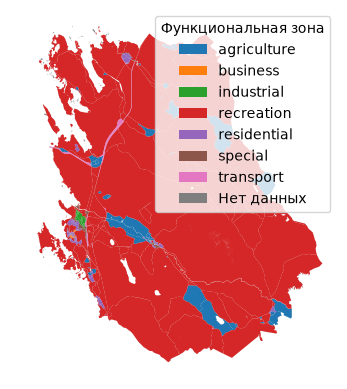

In [9]:
if RUN_ANALYSIS:
    FUNCTIONAL_ZONES_FILE = DATA_DIR / "functional_zones.geojson"
    USE_OSM_FUNCTIONAL_ZONES = False

    if FUNCTIONAL_ZONES_FILE.exists():
        functional_zones = gpd.read_file(FUNCTIONAL_ZONES_FILE).to_crs(analysis_crs)
        print("Читаю локальные функциональные зоны:", FUNCTIONAL_ZONES_FILE)
    elif USE_OSM_FUNCTIONAL_ZONES:
        print("Локальный слой не найден; запрашиваю landuse из OSM.")
        functional_zones = ox.features_from_polygon(
            boundary_polygon, tags={"landuse": True}
        ).reset_index(drop=True)
        functional_zones = functional_zones.rename(
            columns={"landuse": "functional_zone"}
        )
        save_geojson(functional_zones, FUNCTIONAL_ZONES_FILE)
        functional_zones = functional_zones.to_crs(analysis_crs)
    else:
        raise FileNotFoundError(
            f"Не найден слой {FUNCTIONAL_ZONES_FILE}. Подготовьте GeoJSON с полигональной "
            "геометрией и полем functional_zone по инструкции выше, либо явно включите "
            "USE_OSM_FUNCTIONAL_ZONES для ознакомительного запроса к OSM."
        )
    if "functional_zone" not in functional_zones.columns:
        source_column = next(
            (column for column in ["Landuse", "landuse", "land_use"] if column in functional_zones.columns),
            None,
        )
        if source_column is None:
            raise ValueError(
                "В слое требуется поле functional_zone (допустимые исходные имена: "
                "Landuse, landuse, land_use). Переименуйте поле или подготовьте GeoJSON заново."
            )
        functional_zones = functional_zones.rename(
            columns={source_column: "functional_zone"}
        )

    functional_zones = functional_zones.loc[
        functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
    ].copy()
    if functional_zones.empty:
        raise ValueError(
            "В слое функциональных зон нет полигонов. Проверьте геометрию GeoJSON."
        )
    
    functional_zones["functional_zone"] = (
        functional_zones["functional_zone"].astype("string").str.strip().str.lower()
    )
    functional_zones = functional_zones.dropna(subset=["functional_zone"])

    rules = {
        "residential": LandUse.RESIDENTIAL,
        "business": LandUse.BUSINESS,
        "industrial": LandUse.INDUSTRIAL,
        "transport": LandUse.TRANSPORT,
        "recreation": LandUse.RECREATION,
        "agriculture": LandUse.AGRICULTURE,
        "special": LandUse.SPECIAL,
    }
    
    unmapped_zones = set(functional_zones["functional_zone"].unique()) - set(rules)
    if unmapped_zones:
        print(
            "Не сопоставленные категории будут исключены:",
            sorted(unmapped_zones),
            "Добавьте точные значения в словарь rules.",
        )
    blocks = assign_land_use(blocks, functional_zones, rules)
    save_geojson(blocks, DATA_DIR / "blocks_land_use.geojson")
    display(blocks.head())
    land_use_plot = blocks.copy()
    land_use_plot["land_use_label"] = blocks["land_use"].map(
        lambda value: value.value if isinstance(value, LandUse) else value
    ).fillna("Нет данных")
    ax = blocks.plot(color="#dddddd")
    land_use_plot.plot(
        column="land_use_label",
        legend=True,
        legend_kwds={"title": "Функциональная зона"},
        ax=ax,
    ).set_axis_off()
else:
    print("Пауза: RUN_ANALYSIS = False. Расчёты не выполняются.")

### Здания: площади и оценка населения

`impute_buildings` заполняет недостающие характеристики по правилам BlocksNet. Значение `default_living_demand=30` взято из pipeline; фактическое качество оценки зависит от полноты тегов OSM.

Оценка населения по зданиям: 9681


,index,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,count,geometry
0,0,0.0,15.0,1831.489742,1831.489742,577.126243,1254.363498,19.0,15.0,"POLYGON ((592695.084 6713746.638, 592709.539 6..."
1,1,0.0,37.0,3287.899628,3287.899628,2014.593912,1273.305717,65.0,37.0,"POLYGON ((592709.539 6713806.834, 592695.084 6..."
2,2,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,"POLYGON ((594795.349 6705367.276, 594820.227 6..."
3,3,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,"POLYGON ((594820.227 6705363.121, 594795.349 6..."
4,4,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,"POLYGON ((594820.227 6705363.121, 594834.823 6..."


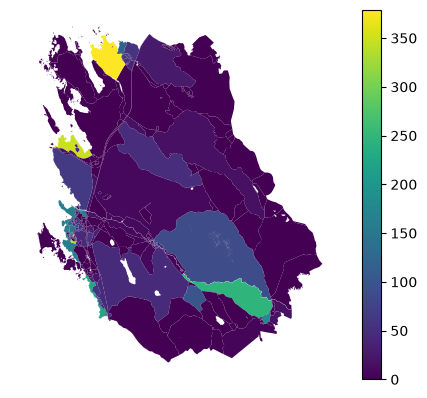

In [10]:
if RUN_ANALYSIS:
    PREPARED_BUILDINGS_FILE = DATA_DIR / "buildings_prepared.geojson"
    AGGREGATED_BUILDINGS_FILE = DATA_DIR / "blocks_buildings.geojson"
    BUILDINGS_FILE = DATA_DIR / "buildings.geojson"
    living_tags = {"residential", "house", "apartments", "detached", "terrace", "dormitory"}
    rebuild_prepared = not PREPARED_BUILDINGS_FILE.exists()

    if rebuild_prepared:
        buildings = load_or_fetch_geojson(
            BUILDINGS_FILE,
            lambda: ox.features_from_polygon(
                boundary_polygon, tags={"building": True}
            ).reset_index(drop=True),
            analysis_crs,
        )
    else:
        buildings = gpd.read_file(PREPARED_BUILDINGS_FILE).to_crs(analysis_crs)
        if BUILDINGS_FILE.exists():
            source_buildings = gpd.read_file(BUILDINGS_FILE).to_crs(analysis_crs)
            source_building_column = next(
                (column for column in source_buildings.columns if column.casefold() == "building"),
                None,
            )
            if source_building_column is not None:
                source_is_living = (
                    source_buildings[source_building_column]
                    .astype("string")
                    .str.strip()
                    .str.lower()
                    .isin(living_tags)
                )
                prepared_has_living = (
                    buildings["is_living"].fillna(False).astype(bool).any()
                    if "is_living" in buildings.columns
                    else False
                )
                if source_is_living.any() and not prepared_has_living:
                    print("Пересоздаю кэш зданий: в исходном слое есть жилые здания.")
                    buildings = source_buildings
                    rebuild_prepared = True

    if rebuild_prepared:
        building_column = next(
            (column for column in buildings.columns if column.casefold() == "building"),
            None,
        )
        if building_column is not None:
            buildings["is_living"] = (
                buildings[building_column]
                .astype("string")
                .str.strip()
                .str.lower()
                .isin(living_tags)
            )
        else:
            buildings["is_living"] = False

        levels_column = next(
            (column for column in buildings.columns if column.casefold() in {"building:levels", "b_levels"}),
            None,
        )
        levels = (
            buildings[levels_column]
            if levels_column is not None
            else pd.Series(index=buildings.index, dtype=object)
        )
        buildings["number_of_floors"] = pd.to_numeric(levels, errors="coerce")
        buildings = impute_buildings(buildings, default_living_demand=30)
        save_geojson(buildings, PREPARED_BUILDINGS_FILE)

    if AGGREGATED_BUILDINGS_FILE.exists() and not rebuild_prepared:
        buildings_blocks = gpd.read_file(AGGREGATED_BUILDINGS_FILE).to_crs(analysis_crs)
        if "block_id" in buildings_blocks.columns:
            buildings_blocks = buildings_blocks.set_index("block_id")
        buildings_blocks = buildings_blocks.reindex(blocks.index)
    else:
        buildings_blocks = aggregate_objects(blocks, buildings)[0]
        buildings_blocks.index = blocks.index
        save_geojson(buildings_blocks, AGGREGATED_BUILDINGS_FILE)
    print("Оценка населения по зданиям, агрегированным по кварталам:", round(buildings_blocks["population"].sum()))
    display(buildings_blocks.head())
    buildings_blocks.plot("population", legend=True).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Школы и детские сады: вместимость по кварталам и целевая сеть

Если отдельного слоя учреждений нет, ячейка сначала использует объекты `school` и `kindergarten` из атрибута `building` исходного `buildings.geojson`, если он действительно присутствует; затем читает соответствующий локальный GeoJSON и, если его нет, запрашивает `amenity=school` / `amenity=kindergarten` в OSM. В текущем сохранённом слое зданий такого тега нет. Подготовленные слои сохраняются как `schools_prepared.geojson` и `kindergartens_prepared.geojson`, агрегаты по кварталам — как `blocks_schools.geojson` и `blocks_kindergartens.geojson`.

Вместимость не заполняется молча минимумом BlocksNet. По умолчанию любая отсутствующая/невалидная `capacity` останавливает расчёт обеспеченности и подсказывает, какой файл/поле исправить. Для ручных данных внесите вместимость и источник в отдельный слой, затем повторно выполните расчётные ячейки сверху вниз. `objects_count` показывает число объектов в квартале.

По кварталам рассчитываются отдельные обеспеченность школами и обеспеченность детскими садами, если оба слоя есть и содержат вместимость. Общая таблица целевых мест рассчитывается независимо от наличия слоёв учреждений. Она не рассчитывает фактическую загруженность; для неё нужны фактическое число учащихся/воспитанников либо занятость мест по учреждению.

,population_scenario,population,population_reference_date,territory_scope,population_source,matches_analysis_boundary,service_type,norm_places_per_1000,target_places,minimum_config_capacity_per_facility,equivalent_facilities_at_minimum_capacity
0,пгт Советский,6911,2025 (ориентировочно),пгт Советский; граница пространственного анализа,информация пользователя со ссылкой на данные п...,True,school,120,830,250,4
1,пгт Советский,6911,2025 (ориентировочно),пгт Советский; граница пространственного анализа,информация пользователя со ссылкой на данные п...,True,kindergarten,61,422,80,6
2,МО Советское городское поселение,8829,2021-10-01,все 10 населённых пунктов МО,"информация с сайта администрации, переданная п...",False,school,120,1060,250,5
3,МО Советское городское поселение,8829,2021-10-01,все 10 населённых пунктов МО,"информация с сайта администрации, переданная п...",False,kindergarten,61,539,80,7
4,Оценка BlocksNet по зданиям,9681,модельная оценка,кварталы текущей пространственной границы,расчёт BlocksNet по данным о зданиях,True,school,120,1162,250,5
5,Оценка BlocksNet по зданиям,9681,модельная оценка,кварталы текущей пространственной границы,расчёт BlocksNet по данным о зданиях,True,kindergarten,61,591,80,8


2026-11-01 23:45:06.595 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-11-01 23:45:06.597 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


В слое зданий школы не найдены; читаю: data\sovetsky\schools.geojson
В слое зданий детские сады не найдены; читаю: data\sovetsky\kindergartens.geojson
Загруженность по данным enrollment сохранена: data\sovetsky\school_occupancy.csv; объектов без данных о числе учащихся/воспитанников: 0


2026-11-01 23:45:06.901 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-11-01 23:45:06.902 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


school: учреждений=1, вместимость=1176, модельных значений=0
Загруженность по данным enrollment сохранена: data\sovetsky\kindergarten_occupancy.csv; объектов без данных о числе учащихся/воспитанников: 0
kindergarten: учреждений=4, вместимость=555, модельных значений=0


,population_scenario,population,population_reference_date,territory_scope,population_source,matches_analysis_boundary,service_type,norm_places_per_1000,target_places,minimum_config_capacity_per_facility,equivalent_facilities_at_minimum_capacity,observed_capacity,modelled_capacity,remaining_target_places
0,пгт Советский,6911,2025 (ориентировочно),пгт Советский; граница пространственного анализа,информация пользователя со ссылкой на данные п...,True,school,120,830,250,4,1176.0,0.0,0
1,пгт Советский,6911,2025 (ориентировочно),пгт Советский; граница пространственного анализа,информация пользователя со ссылкой на данные п...,True,kindergarten,61,422,80,6,555.0,0.0,0
2,МО Советское городское поселение,8829,2021-10-01,все 10 населённых пунктов МО,"информация с сайта администрации, переданная п...",False,school,120,1060,250,5,NaN,NaN,<NA>
3,МО Советское городское поселение,8829,2021-10-01,все 10 населённых пунктов МО,"информация с сайта администрации, переданная п...",False,kindergarten,61,539,80,7,NaN,NaN,<NA>
4,Оценка BlocksNet по зданиям,9681,модельная оценка,кварталы текущей пространственной границы,расчёт BlocksNet по данным о зданиях,True,school,120,1162,250,5,1176.0,0.0,0
5,Оценка BlocksNet по зданиям,9681,модельная оценка,кварталы текущей пространственной границы,расчёт BlocksNet по данным о зданиях,True,kindergarten,61,591,80,8,555.0,0.0,36.0


Сохранены подготовленные школы: data\sovetsky\schools_prepared.geojson
Сохранены школы по кварталам: data\sovetsky\blocks_schools.geojson


,capacity,objects_count
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0


Сохранены подготовленные детские сады: data\sovetsky\kindergartens_prepared.geojson
Сохранены детские сады по кварталам: data\sovetsky\blocks_kindergartens.geojson


,capacity,objects_count
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0


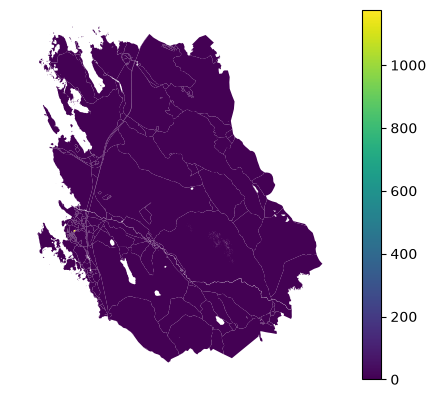

In [11]:
if RUN_ANALYSIS:
    BUILDINGS_FILE = DATA_DIR / "buildings.geojson"
    from math import ceil
    ALLOW_IMPUTED_SERVICE_CAPACITY = False
    target_population_scenarios = {
        "пгт Советский (только население посёлка)": {
            "population": 6911,
            "reference_date": "2025 (ориентировочно)",
            "territory_scope": "только пгт Советский; меньше границы анализа",
            "population_source": "информация пользователя со ссылкой на данные по пгт",
            "matches_analysis_boundary": False,
        },
        "МО Советское городское поселение": {
            "population": 8829,
            "reference_date": "2021-10-01",
            "territory_scope": "все 10 населённых пунктов МО",
            "population_source": "информация с сайта администрации, переданная пользователем",
            "matches_analysis_boundary": True,
        },
        "МО Советское городское поселение (оценка на начало 2025)": {
            "population": 9604,
            "reference_date": "начало 2025 (оценка; уточнить первичный источник)",
            "territory_scope": "все 10 населённых пунктов МО",
            "population_source": "оценка, переданная пользователем; вторичный источник Wikiwand со ссылкой на оценки Росстата",
            "matches_analysis_boundary": True,
        },
        "Оценка BlocksNet по зданиям": {
            "population": round(buildings_blocks["population"].sum()),
            "reference_date": "модельная оценка",
            "territory_scope": "кварталы текущей пространственной границы",
            "population_source": "расчёт BlocksNet по данным о зданиях",
            "matches_analysis_boundary": True,
        },
    }
    target_rows = []
    for scenario_name, scenario in target_population_scenarios.items():
        scenario_population = scenario["population"]
        for service_type in ["school", "kindergarten"]:
            service_config = service_types_config[service_type]
            required_places = int(
                ceil(
                    scenario_population * service_config["demand"] / 1000
                )
            )
            minimum_capacity = int(
                service_types_config.units.loc[
                    service_types_config.units.service_type.eq(service_type), "capacity"
                ].min()
            )
            target_rows.append(
                {
                    "population_scenario": scenario_name,
                    "population": scenario_population,
                    "population_reference_date": scenario["reference_date"],
                    "territory_scope": scenario["territory_scope"],
                    "population_source": scenario["population_source"],
                    "matches_analysis_boundary": scenario["matches_analysis_boundary"],
                    "service_type": service_type,
                    "norm_places_per_1000": service_config["demand"],
                    "target_places": required_places,
                    "minimum_config_capacity_per_facility": minimum_capacity,
                    "equivalent_facilities_at_minimum_capacity": int(
                        ceil(required_places / minimum_capacity)
                    ),
                }
            )
    target_network_df = pd.DataFrame(target_rows)
    display(target_network_df)
    TARGET_NETWORK_FILE = DATA_DIR / "target_education_network.csv"
    target_network_df.to_csv(TARGET_NETWORK_FILE, index=False)
    SCHOOLS_FILE = DATA_DIR / "schools.geojson"
    KINDERGARTENS_FILE = DATA_DIR / "kindergartens.geojson"
    PREPARED_SCHOOLS_FILE = DATA_DIR / "schools_prepared.geojson"
    PREPARED_KINDERGARTENS_FILE = DATA_DIR / "kindergartens_prepared.geojson"
    AGGREGATED_SCHOOLS_FILE = DATA_DIR / "blocks_schools.geojson"
    AGGREGATED_KINDERGARTENS_FILE = DATA_DIR / "blocks_kindergartens.geojson"

    schools = gpd.GeoDataFrame(geometry=gpd.GeoSeries([], crs=analysis_crs), crs=analysis_crs)
    kindergartens = gpd.GeoDataFrame(geometry=gpd.GeoSeries([], crs=analysis_crs), crs=analysis_crs)

    if BUILDINGS_FILE.exists():
        building_objects = gpd.read_file(BUILDINGS_FILE).to_crs(analysis_crs)
        building_column = next(
            (column for column in building_objects.columns if column.casefold() == "building"),
            None,
        )
        if building_column is not None:
            building_types = (
                building_objects[building_column]
                .astype("string")
                .str.strip()
                .str.lower()
            )
            schools = building_objects.loc[building_types == "school"].copy()
            kindergartens = building_objects.loc[building_types == "kindergarten"].copy()
            print("Найдено школ в слое зданий:", len(schools))
            print("Найдено детских садов в слое зданий:", len(kindergartens))

    if schools.empty:
        if SCHOOLS_FILE.exists():
            schools = gpd.read_file(SCHOOLS_FILE).to_crs(analysis_crs)
            print("В слое зданий школы не найдены; читаю:", SCHOOLS_FILE)
        else:
            schools = load_or_fetch_geojson(
                SCHOOLS_FILE,
                lambda: ox.features_from_polygon(
                    boundary_polygon, tags={"amenity": "school"}
                ).reset_index(drop=True),
                analysis_crs,
            )

    if kindergartens.empty:
        if KINDERGARTENS_FILE.exists():
            kindergartens = gpd.read_file(KINDERGARTENS_FILE).to_crs(analysis_crs)
            print("В слое зданий детские сады не найдены; читаю:", KINDERGARTENS_FILE)
        else:
            kindergartens = load_or_fetch_geojson(
                KINDERGARTENS_FILE,
                lambda: ox.features_from_polygon(
                    boundary_polygon, tags={"amenity": "kindergarten"}
                ).reset_index(drop=True),
                analysis_crs,
            )

    def prepare_service_layer(service_layer, service_type, source_file, prepared_file, aggregated_file):
        if service_layer.empty:
            print(f"Учреждения {service_type} не найдены: {source_file}")
            return None, None

        service_layer = service_layer.loc[service_layer.geometry.notna()].copy()
        if service_layer.empty:
            raise ValueError(f"В {source_file} нет объектов с геометрией.")
        if "capacity" not in service_layer.columns:
            service_layer["capacity"] = pd.NA
        service_layer["capacity"] = pd.to_numeric(service_layer["capacity"], errors="coerce")
        invalid_capacity = (
            service_layer["capacity"].isna()
            | ~service_layer["capacity"].map(lambda value: pd.notna(value) and value != float("inf") and value != float("-inf"))
            | service_layer["capacity"].le(0)
        )
        service_layer["capacity_is_imputed"] = False
        if invalid_capacity.any():
            if not ALLOW_IMPUTED_SERVICE_CAPACITY:
                raise ValueError(
                    f"В {source_file} у {int(invalid_capacity.sum())} объектов {service_type} "
                    "отсутствует или некорректна capacity. Добавьте положительную вместимость "
                    "в местах по каждому учреждению и поле capacity_source в GeoJSON. "
                    "Для предварительной оценки явно включите ALLOW_IMPUTED_SERVICE_CAPACITY = True; "
                    "такая вместимость будет помечена как модельная, а не фактическая."
                )
            service_layer.loc[invalid_capacity, "capacity"] = pd.NA
            service_layer = impute_services(service_layer, service_type)
            service_layer.loc[invalid_capacity, "capacity_is_imputed"] = True

        if "capacity_source" not in service_layer.columns:
            service_layer["capacity_source"] = "не указан; проверьте источник"
        service_layer.loc[
            service_layer["capacity_is_imputed"], "capacity_source"
        ] = "BlocksNet imputation; модельное допущение"

        if "enrollment" in service_layer.columns:
            raw_enrollment = service_layer["enrollment"]
            service_layer["enrollment"] = pd.to_numeric(raw_enrollment, errors="coerce")
            invalid_enrollment_format = raw_enrollment.notna() & service_layer["enrollment"].isna()
            if invalid_enrollment_format.any():
                raise ValueError(
                    f"В {source_file} есть enrollment, которое не является числом. "
                    "Исправьте значения или оставьте поле пустым."
                )
            invalid_enrollment = service_layer["enrollment"].notna() & service_layer["enrollment"].lt(0)
            if invalid_enrollment.any():
                raise ValueError(
                    f"В {source_file} есть отрицательное enrollment. Исправьте данные по учреждению."
                )
            occupancy_file = DATA_DIR / f"{service_type}_occupancy.csv"
            occupancy_columns = [
                column for column in [
                    "name", "address", "capacity_source", "capacity", "enrollment",
                    "capacity_is_imputed",
                ]
                if column in service_layer.columns
            ]
            occupancy_df = service_layer[occupancy_columns].copy()
            occupancy_df["vacant_capacity"] = (
                occupancy_df["capacity"] - occupancy_df["enrollment"]
            ).where(~occupancy_df["capacity_is_imputed"])
            occupancy_df["occupancy_rate"] = (
                occupancy_df["enrollment"] / occupancy_df["capacity"]
            ).where(~occupancy_df["capacity_is_imputed"])
            missing_enrollment_count = int(occupancy_df["enrollment"].isna().sum())
            occupancy_df.to_csv(occupancy_file, index=False)
            print(
                f"Загруженность по данным enrollment сохранена: {occupancy_file}; "
                f"объектов без данных о числе учащихся/воспитанников: {missing_enrollment_count}"
            )
        else:
            print(
                f"Для расчёта фактической загруженности {service_type} добавьте "
                "поле enrollment (число учащихся/воспитанников по учреждению)."
            )

        save_geojson(service_layer, prepared_file)
        aggregated = aggregate_objects(blocks, service_layer)[0]
        aggregated.index = blocks.index
        aggregated = aggregated.rename(columns={"count": "objects_count"})
        save_geojson(aggregated, aggregated_file)
        print(
            f"{service_type}: учреждений={len(service_layer)}, "
            f"вместимость={service_layer['capacity'].sum():g}, "
            f"модельных значений={int(service_layer['capacity_is_imputed'].sum())}"
        )
        return service_layer, aggregated

    schools, schools_blocks = prepare_service_layer(
        schools, "school", SCHOOLS_FILE, PREPARED_SCHOOLS_FILE, AGGREGATED_SCHOOLS_FILE
    )
    kindergartens, kindergartens_blocks = prepare_service_layer(
        kindergartens, "kindergarten", KINDERGARTENS_FILE,
        PREPARED_KINDERGARTENS_FILE, AGGREGATED_KINDERGARTENS_FILE
    )

    capacity_by_service = {
        "school": schools.loc[~schools["capacity_is_imputed"], "capacity"].sum() if schools is not None else pd.NA,
        "kindergarten": kindergartens.loc[~kindergartens["capacity_is_imputed"], "capacity"].sum() if kindergartens is not None else pd.NA,
    }
    target_network_df["observed_capacity"] = target_network_df["service_type"].map(capacity_by_service)
    target_network_df["modelled_capacity"] = target_network_df["service_type"].map(
        {
            "school": schools.loc[schools["capacity_is_imputed"], "capacity"].sum() if schools is not None else pd.NA,
            "kindergarten": kindergartens.loc[kindergartens["capacity_is_imputed"], "capacity"].sum() if kindergartens is not None else pd.NA,
        }
    )
    boundary_matches = target_network_df["matches_analysis_boundary"]
    target_network_df.loc[
        ~boundary_matches, ["observed_capacity", "modelled_capacity"]
    ] = pd.NA
    target_network_df["remaining_target_places"] = target_network_df.apply(
        lambda row: max(0, row["target_places"] - row["observed_capacity"])
        if pd.notna(row["observed_capacity"])
        else pd.NA,
        axis=1,
    )
    display(target_network_df)
    target_network_df.to_csv(TARGET_NETWORK_FILE, index=False)

    if schools_blocks is not None:
        print("Сохранены подготовленные школы:", PREPARED_SCHOOLS_FILE)
        print("Сохранены школы по кварталам:", AGGREGATED_SCHOOLS_FILE)
        display(schools_blocks[["capacity", "objects_count"]].head())
        schools_blocks.plot("capacity", legend=True).set_axis_off()
    if kindergartens_blocks is not None:
        print("Сохранены подготовленные детские сады:", PREPARED_KINDERGARTENS_FILE)
        print("Сохранены детские сады по кварталам:", AGGREGATED_KINDERGARTENS_FILE)
        display(kindergartens_blocks[["capacity", "objects_count"]].head())
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Пешеходный граф и время между кварталами

В опубликованном наборе BlocksNet-data нет готового графа для пгт Советский, поэтому при расчёте используется OpenStreetMap через IduEdu `0.4.1` (Overpass). Режим: пешком (`walk`), не интермодальный. IduEdu сохраняет время рёбер в минутах (`time_min`), и матрица доступности тоже выражена в минутах. Граф повторно используется из локального GraphML в `data/sovetsky`. Для матрицы времени используется CSV: она не является геометрическим слоем.

In [12]:
if RUN_ANALYSIS:
    graph_in_memory = globals().get("graph")
    graph = None
    if GRAPH_FILE.exists() and GRAPH_FILE.stat().st_size > 0:
        try:
            graph = nx.read_graphml(GRAPH_FILE, node_type=int)
            print("Читаю сохранённый пешеходный граф:", GRAPH_FILE)
        except (nx.NetworkXError, OSError, ValueError) as exc:
            print("Сохранённый граф повреждён; пересоздаю:", exc)

    if graph is None:
        if graph_in_memory is None:
            graph = get_accessibility_graph(boundaries_wgs84, "walk")
            print("Пешеходный граф получен из OpenStreetMap.")
        else:
            graph = graph_in_memory
            print("Использую пешеходный граф, уже загруженный в ядро.")

        graph_to_save = graph.copy()
        for _, attributes in graph_to_save.nodes(data=True):
            for key in list(attributes):
                if key not in {"x", "y"}:
                    del attributes[key]
        if graph_to_save.is_multigraph():
            edge_attributes = graph_to_save.edges(keys=True, data=True)
        else:
            edge_attributes = graph_to_save.edges(data=True)
        for edge in edge_attributes:
            attributes = edge[-1]
            for key in list(attributes):
                if key != "time_min":
                    del attributes[key]
        for key in list(graph_to_save.graph):
            if key != "crs":
                del graph_to_save.graph[key]

        temporary_graph_file = GRAPH_FILE.with_name(GRAPH_FILE.name + ".tmp")
        nx.write_graphml(graph_to_save, temporary_graph_file)
        temporary_graph_file.replace(GRAPH_FILE)
        print("Пешеходный граф сохранён:", GRAPH_FILE)

    if MATRIX_FILE.exists():
        acc_mx = pd.read_csv(MATRIX_FILE, index_col=0)
        acc_mx.index = pd.to_numeric(acc_mx.index).astype(int)
        acc_mx.columns = pd.to_numeric(acc_mx.columns).astype(int)
        acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)
        print("Читаю сохранённую матрицу времени:", MATRIX_FILE)
    else:
        acc_mx = calculate_accessibility_matrix(blocks, graph)
        acc_mx.index = blocks.index
        acc_mx.columns = blocks.index
        acc_mx.to_csv(MATRIX_FILE, index=True, index_label="block_id")
        print("Матрица времени сохранена:", MATRIX_FILE)

    print("Форма матрицы времени (минуты):", acc_mx.shape)
    display(acc_mx.iloc[:5, :5])
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

Читаю сохранённый пешеходный граф: data\sovetsky\sovetsky_walk.graphml
Читаю сохранённую матрицу времени: data\sovetsky\accessibility_walk_minutes.csv
Форма матрицы времени (минуты): (814, 814)


,0,1,2,3,4
0,0.00,29.55,135.600,177.80,141.200
1,29.55,0.00,162.500,204.80,168.100
2,135.60,162.50,0.000,42.38,5.723
3,177.80,204.80,42.380,0.00,48.000
4,141.20,168.10,5.723,48.00,0.000


### Конкурентная обеспеченность школами

Для оценки используются спрос из населения, вместимость школ по кварталам и время пешком в минутах. Порог времени и норма спроса берутся из `service_types_config["school"]` BlocksNet; проверьте их значения перед запуском. Результат и таблица связей между кварталами сохраняются отдельно.

2026-11-01 23:47:08.384 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-11-01 23:47:08.386 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-11-01 23:47:08.407 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-11-01 23:47:08.426 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-11-01 23:47:08.919 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


school: порог доступности=15 мин, норматив спроса=120 мест/1000 жителей


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,3,0,3,0,0,0,0,0,0.0,0.0
1,8,0,8,0,0,0,0,0,0.0,0.0
2,0,0,0,0,0,0,0,0,NaN,NaN
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN


,,value
source,target,
21,293,2.0
29,293,20.0
35,293,6.0
36,293,11.0
38,293,2.0


2026-11-01 23:47:09.479 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-11-01 23:47:09.480 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-11-01 23:47:09.493 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-11-01 23:47:09.510 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-11-01 23:47:09.594 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


kindergarten: порог доступности=7 мин, норматив спроса=61 мест/1000 жителей


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,2,0,2,0,0,0,0,0,0.0,0.0
1,4,0,4,0,0,0,0,0,0.0,0.0
2,0,0,0,0,0,0,0,0,NaN,NaN
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN


,,value
source,target,
21,252,1.0
29,487,10.0
52,252,1.0
199,487,1.0
200,291,2.0


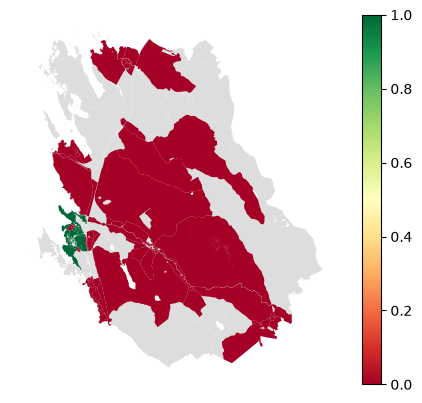

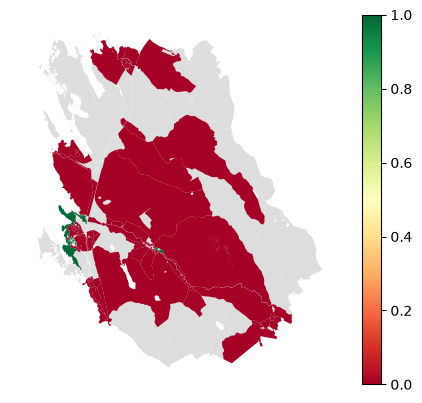

In [13]:
if RUN_ANALYSIS:

    def calculate_service_provision(service_type, service_layer, service_blocks, output_file, links_file):
        if service_layer is None or service_blocks is None:
            print(
                f"Обеспеченность {service_type} не рассчитана: нет слоя учреждений "
                "с проверенной вместимостью. Добавьте GeoJSON согласно инструкции выше."
            )
            return None
        demand_input = buildings_blocks[["population"]].join(service_blocks[["capacity"]])
        service_config = service_types_config[service_type]
        provision, links = competitive_provision(
            demand_input,
            acc_mx,
            service_config["accessibility"],
            service_config["demand"],
        )
        save_geojson(blocks.join(provision), output_file)
        links.to_csv(links_file)
        print(
            f"{service_type}: порог доступности={service_config['accessibility']} мин, "
            f"норматив спроса={service_config['demand']} мест/1000 жителей"
        )
        display(provision.head())
        display(links.head())
        ax = blocks.plot(color="#dddddd")
        blocks.join(provision).plot(
            column="provision_strong", ax=ax, cmap="RdYlGn", vmin=0, vmax=1, legend=True
        ).set_axis_off()
        return provision

    school_provision_file = DATA_DIR / "blocks_school_provision.geojson"
    school_links_file = DATA_DIR / "school_provision_links.csv"
    provision_df = calculate_service_provision(
        "school", schools, schools_blocks, school_provision_file, school_links_file
    )
    kindergarten_provision_file = DATA_DIR / "blocks_kindergarten_provision.geojson"
    kindergarten_links_file = DATA_DIR / "kindergarten_provision_links.csv"
    kindergarten_provision_df = calculate_service_provision(
        "kindergarten", kindergartens, kindergartens_blocks,
        kindergarten_provision_file, kindergarten_links_file
    )
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Плотность застройки и морфотипы

`calculate_density_indicators` рассчитывает индикаторы, включая `FSI`, `GSI`, `MXI`, `L`, `OSR` и доли площадей. Далее те же индикаторы классифицируются двумя методами: Spacematrix и Стрелки. Для пустых кварталов возможны неопределённые значения; они сохраняются как есть.

Исправлена геометрия лесного слоя: 3 объектов починены в памяти через make_valid; исходный GeoJSON не изменён.
При ремонте отброшено неполигональных частей: 1.
Показатели плотности: (814, 12)
Классификация территории:


,blocks
territory_class,
Незастроенная территория вне распознанных лесных полигонов,354
Застроенная территория,283
"Незастроенная территория, пересекается с лесной зоной",177


Источник лесных полигонов: forest_fund.geojson


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,6.512356e+05,1831.489742,1831.489742,577.126243,1254.363498,0.002812,0.002812,0.315113,1.0,354.576962,0.315113,0.684887
1,7.629516e+06,3287.899628,3287.899628,2014.593912,1273.305717,0.000431,0.000431,0.612730,1.0,2319.483265,0.612730,0.387270
2,5.117240e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
3,1.220201e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
4,5.533625e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN


Морфотипы Spacematrix по кварталам:


,l,fsi,mxi,cluster,morphotype,morphotype_ru
0,1.0,0.002812,0.315113,8.0,low-rise low-density mixed-use,"Малоэтажная, низкой плотности, смешанная"
1,1.0,0.000431,0.612730,0.0,low-rise low-density mixed-use,"Малоэтажная, низкой плотности, смешанная"
2,0.0,0.000000,0.000000,NaN,not applicable: unbuilt,Не применяется: незастроенная территория
3,0.0,0.000000,0.000000,NaN,not applicable: unbuilt,Не применяется: незастроенная территория
4,0.0,0.000000,0.000000,NaN,not applicable: unbuilt,Не применяется: незастроенная территория


Центры кластеров Spacematrix:


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype,morphotype_ru
cluster,,,,,,,,
0,1.0,0.019597,0.522501,low-rise,low-density,mixed-use,low-rise low-density mixed-use,"Малоэтажная, низкой плотности, смешанная"
1,5.0,1.394952,0.853141,mid-rise,None,residential,mid-rise residential,"Среднеэтажная, жилая"
2,1.0,0.218781,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential,"Малоэтажная, низкой плотности, нежилая"
3,2.0,0.441637,0.860693,low-rise,low-density,residential,low-rise low-density residential,"Малоэтажная, низкой плотности, жилая"
4,5.0,2.204724,0.846026,mid-rise,high-density,residential,mid-rise high-density residential,"Среднеэтажная, высокой плотности, жилая"


Морфотипы Стрелки:


,l,fsi,mxi,morphotype,morphotype_ru
0,1.0,0.002812,0.315113,individual residential,Индивидуальная жилая застройка
1,1.0,0.000431,0.612730,individual residential,Индивидуальная жилая застройка
2,0.0,0.000000,0.000000,not applicable: unbuilt,Не применяется: незастроенная территория
3,0.0,0.000000,0.000000,not applicable: unbuilt,Не применяется: незастроенная территория
4,0.0,0.000000,0.000000,not applicable: unbuilt,Не применяется: незастроенная территория


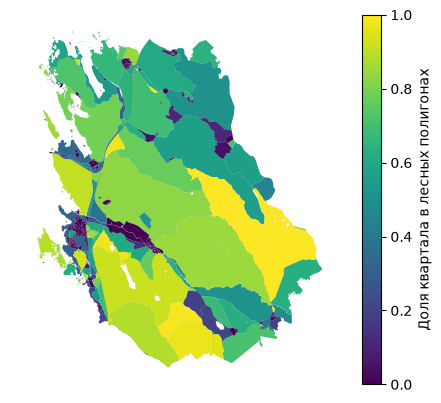

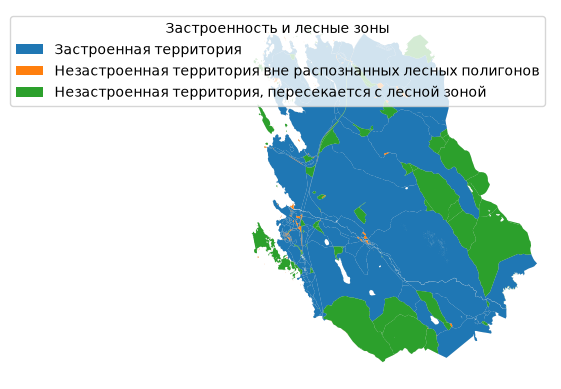

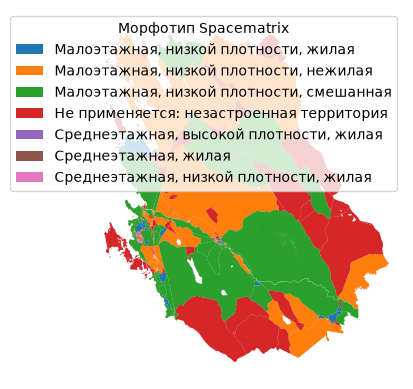

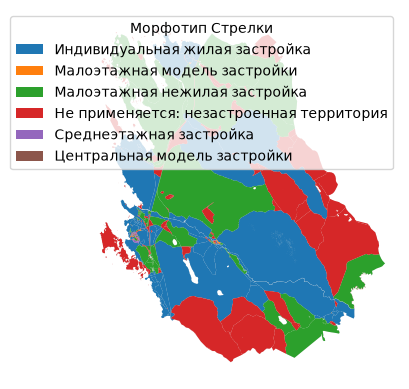

In [16]:
if RUN_ANALYSIS:
    import shapely

    buildings_blocks["site_area"] = buildings_blocks.area
    density_df = calculate_density_indicators(buildings_blocks)
    density_df = density_df.rename_axis(index="block_id").reindex(blocks.index)
    density_df["osr"] = density_df["osr"].replace([float("inf"), float("-inf")], float("nan"))

    building_present = (
        density_df["footprint_area"].fillna(0).gt(0)
        | density_df["build_floor_area"].fillna(0).gt(0)
    )
    zone_name_columns = [
        column for column in ["name", "full_name"] if column in functional_zones.columns
    ]
    forest_union = None
    if FOREST_FUND_FILE.exists():
        forest_layer = gpd.read_file(FOREST_FUND_FILE).to_crs(analysis_crs)
        forest_layer = forest_layer.loc[
            forest_layer.geom_type.isin(["Polygon", "MultiPolygon"])
        ]
        if forest_layer.empty:
            raise ValueError(
                f"В {FOREST_FUND_FILE} нет полигональных объектов. "
                "Подготовьте полигональный слой земель лесного фонда."
            )
        forest_polygons = []
        repaired_geometry_count = 0
        ignored_non_polygon_parts = 0
        for geometry in forest_layer.geometry:
            if not geometry.is_valid:
                geometry = shapely.make_valid(geometry)
                repaired_geometry_count += 1
            parts_to_check = [geometry]
            while parts_to_check:
                part = parts_to_check.pop()
                if part.geom_type == "Polygon":
                    forest_polygons.append(part)
                elif part.geom_type in ["MultiPolygon", "GeometryCollection"]:
                    parts_to_check.extend(part.geoms)
                else:
                    ignored_non_polygon_parts += 1
        if not forest_polygons:
            raise ValueError(
                f"В {FOREST_FUND_FILE} после проверки геометрии не осталось полигонов. "
                "Проверьте исходный слой."
            )
        forest_union = shapely.union_all(forest_polygons)
        if repaired_geometry_count:
            print(
                f"Исправлена геометрия лесного слоя: {repaired_geometry_count} объектов "
                "починены в памяти через make_valid; исходный GeoJSON не изменён."
            )
        if ignored_non_polygon_parts:
            print(
                f"При ремонте отброшено неполигональных частей: {ignored_non_polygon_parts}."
            )
        forest_zone_source = "forest_fund.geojson"
    elif zone_name_columns:
        zone_names = (
            functional_zones[zone_name_columns]
            .fillna("")
            .astype("string")
            .agg(" ".join, axis=1)
        )
        forest_zones = functional_zones.loc[
            zone_names.str.contains("лес", case=False, regex=False, na=False)
        ]
        if not forest_zones.empty:
            forest_union = forest_zones.geometry.union_all()
            forest_zone_source = "functional_zones: name/full_name contains лес"
            print(
                "Предупреждение: forest_fund.geojson не найден; "
                "лесные территории распознаны только по названиям функциональных зон. "
                "Юридическая категория земель так не подтверждается."
            )
        else:
            forest_zone_source = "лесные полигоны не распознаны"
    else:
        forest_zone_source = "нет полей name/full_name или forest_fund.geojson"

    block_area = blocks.geometry.area
    forest_zone_share = pd.Series(0.0, index=blocks.index, name="forest_zone_share")
    if forest_union is not None:
        forest_intersection_area = blocks.geometry.intersection(forest_union).area
        forest_zone_share = (
            forest_intersection_area.div(block_area.where(block_area.gt(0)))
            .fillna(0)
            .clip(0, 1)
            .rename("forest_zone_share")
        )

    development_df = pd.DataFrame(index=blocks.index)
    development_df["development_status"] = building_present.map(
        {True: "Застроенный", False: "Незастроенный по слою зданий"}
    )
    development_df["forest_zone_share"] = forest_zone_share
    development_df["forest_zone_data_source"] = forest_zone_source
    development_df["territory_class"] = "Иная незастроенная территория"
    development_df.loc[building_present, "territory_class"] = "Застроенная территория"
    if forest_union is not None:
        development_df.loc[
            ~building_present & forest_zone_share.gt(0), "territory_class"
        ] = "Незастроенная территория, пересекается с лесной зоной"
        development_df.loc[
            ~building_present & forest_zone_share.eq(0), "territory_class"
        ] = "Незастроенная территория вне распознанных лесных полигонов"
    else:
        development_df.loc[
            ~building_present, "territory_class"
        ] = "Незастроенная территория, лесная принадлежность не определена"

    DENSITY_FILE = DATA_DIR / "density_indicators.csv"
    density_df.to_csv(DENSITY_FILE)

    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
    strelka_df = get_strelka_morphotypes(density_df)

    height_labels_ru = {
        "low-rise": "Малоэтажная",
        "mid-rise": "Среднеэтажная",
        "high-mid-rise": "Повышенной этажности",
        "high-rise": "Высотная",
        "tower": "Башенная",
    }
    density_labels_ru = {
        "low-density": "низкой плотности",
        "high-density": "высокой плотности",
    }
    use_labels_ru = {
        "non-residential": "нежилая",
        "mixed-use": "смешанная",
        "residential": "жилая",
    }

    def translate_spacematrix_morphotype(value):
        if pd.isna(value):
            return "Нет данных"
        value = str(value)
        height = next(
            (label for source, label in height_labels_ru.items() if value.startswith(source)),
            "Застройка",
        )
        density = next(
            (label for source, label in density_labels_ru.items() if source in value),
            None,
        )
        use = next(
            (label for source, label in use_labels_ru.items() if source in value),
            None,
        )
        return ", ".join(part for part in [height, density, use] if part)

    strelka_labels_ru = {
        "low-rise non-residential": "Малоэтажная нежилая застройка",
        "individual residential": "Индивидуальная жилая застройка",
        "low-rise model": "Малоэтажная модель застройки",
        "mid-rise": "Среднеэтажная застройка",
        "mid-rise non-residential": "Среднеэтажная нежилая застройка",
        "mid-rise microdistrict": "Среднеэтажный микрорайон",
        "mid-rise block": "Среднеэтажный квартал",
        "central model": "Центральная модель застройки",
        "high-rise non-residential": "Высотная нежилая застройка",
        "high-rise soviet microdistrict": "Высотный советский микрорайон",
        "high-rise modern microdistrict": "Высотный современный микрорайон",
    }
    spacematrix_df["morphotype_ru"] = spacematrix_df["morphotype"].map(
        translate_spacematrix_morphotype
    )
    unbuilt_blocks = ~building_present
    spacematrix_df.loc[unbuilt_blocks, "morphotype"] = "not applicable: unbuilt"
    spacematrix_df.loc[
        unbuilt_blocks, "morphotype_ru"
    ] = "Не применяется: незастроенная территория"
    spacematrix_clusters["morphotype_ru"] = spacematrix_clusters["morphotype"].map(
        translate_spacematrix_morphotype
    )
    strelka_df["morphotype_ru"] = strelka_df["morphotype"].map(
        lambda value: strelka_labels_ru.get(value, "Нет данных")
    )
    strelka_df.loc[unbuilt_blocks, "morphotype"] = "not applicable: unbuilt"
    strelka_df.loc[
        unbuilt_blocks, "morphotype_ru"
    ] = "Не применяется: незастроенная территория"

    print("Показатели плотности:", density_df.shape)
    print("Классификация территории:")
    display(development_df["territory_class"].value_counts().rename("blocks").to_frame())
    print("Источник лесных полигонов:", forest_zone_source)
    display(density_df.head())
    print("Морфотипы Spacematrix по кварталам:")
    display(spacematrix_df[["l", "fsi", "mxi", "cluster", "morphotype", "morphotype_ru"]].head())
    print("Центры кластеров Spacematrix:")
    display(spacematrix_clusters.head())
    print("Морфотипы Стрелки:")
    display(strelka_df[["l", "fsi", "mxi", "morphotype", "morphotype_ru"]].head())

    ax = blocks.plot(color="#dddddd")
    blocks.join(development_df).plot(
        "forest_zone_share",
        ax=ax,
        vmin=0,
        vmax=1,
        legend=True,
        legend_kwds={"label": "Доля квартала в лесных полигонах"},
    ).set_axis_off()

    ax = blocks.plot(color="#dddddd")
    blocks.join(development_df).plot(
        "territory_class",
        legend=True,
        legend_kwds={"title": "Застроенность и лесные зоны"},
        ax=ax,
    ).set_axis_off()

    ax = blocks.plot(color="#dddddd")
    blocks.join(spacematrix_df[["morphotype_ru"]]).plot(
        "morphotype_ru", legend=True, legend_kwds={"title": "Морфотип Spacematrix"}, ax=ax
    ).set_axis_off()
    ax = blocks.plot(color="#dddddd")
    blocks.join(strelka_df[["morphotype_ru"]]).plot(
        "morphotype_ru", legend=True, legend_kwds={"title": "Морфотип Стрелки"}, ax=ax
    ).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Доступность территории

Рассчитывается взвешенная площадью доступность с помощью `area_accessibility(acc_mx, buildings_blocks)`. Результат привязывается к кварталам, чтобы увидеть, какие участки лучше обеспечены по пешеходному времени от всех остальных кварталов.

Взвешенное по площади время до квартала (минуты):


,area_accessibility
count,814.000000
mean,204.919656
std,42.253304
min,147.832093
25%,176.479478
50%,193.083664
75%,227.383882
max,333.554342


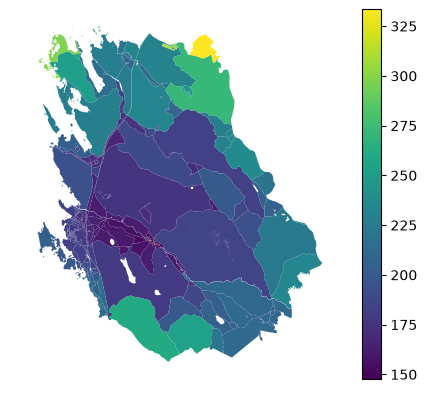

In [17]:
if RUN_ANALYSIS:
    area_acc = area_accessibility(acc_mx, buildings_blocks)
    area_acc = area_acc.reindex(blocks.index)
    AREA_ACCESSIBILITY_FILE = DATA_DIR / "area_accessibility.csv"
    area_acc.to_csv(AREA_ACCESSIBILITY_FILE)
    blocks_with_access = blocks.join(area_acc)
    print("Взвешенное по площади время до квартала (минуты):")
    display(area_acc.describe())
    blocks_with_access.plot("area_accessibility", legend=True).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Финальный слой и проверка

После расчётов объединяются итоговые слои кварталов, обеспеченности, плотности, морфотипов и доступности. Набор сохраняется как GeoJSON и CSV; затем можно быстро проверить размеры и отсутствие дубликатов по `block_id`.

In [18]:
if RUN_ANALYSIS:
    # 1. Оставляем только population, так как objects_count нет
    building_summary = buildings_blocks[["population"]].rename(
        columns={
            "population": "building_population_estimate",
        }
    )
    
    # 2. Блок school_summary мы пропускаем (закомментировали), 
    # так как он состоял только из отсутствующего objects_count
    # school_summary = schools_blocks[["objects_count"]].rename(
    #     columns={"objects_count": "school_objects_count"}
    # )
    
    spacematrix_result = spacematrix_df[["morphotype", "morphotype_ru"]].rename(
        columns={
            "morphotype": "spacematrix_morphotype",
            "morphotype_ru": "spacematrix_morphotype_ru",
        }
    )
    strelka_result = strelka_df[["morphotype", "morphotype_ru"]].rename(
        columns={
            "morphotype": "strelka_morphotype",
            "morphotype_ru": "strelka_morphotype_ru",
        }
    )
    
    density_columns = [
        "site_area", "footprint_area", "build_floor_area", "living_area",
        "non_living_area", "fsi", "gsi", "mxi", "l", "osr",
        "share_living", "share_non_living",
    ]
    
    # 3. Убираем .join(school_summary) из цепочки объединения
    final_layer = blocks.join(building_summary)
    if provision_df is not None:
        final_layer = final_layer.join(provision_df)
    else:
        final_layer["provision_strong"] = pd.NA
        final_layer["provision_weak"] = pd.NA
    if kindergarten_provision_df is not None:
        kindergarten_columns = {
            column: f"kindergarten_{column}"
            for column in kindergarten_provision_df.columns
        }
        final_layer = final_layer.join(
            kindergarten_provision_df.rename(columns=kindergarten_columns)
        )
    final_layer = (
        final_layer.join(density_df[density_columns])
        .join(development_df)
        .join(spacematrix_result)
        .join(strelka_result)
        .join(area_acc)
    )
    
    final_layer.index.name = "block_id"
    FINAL_GEOJSON_FILE = DATA_DIR / "sovetsky_pipeline_results.geojson"
    FINAL_CSV_FILE = DATA_DIR / "sovetsky_pipeline_results.csv"
    save_geojson(final_layer, FINAL_GEOJSON_FILE)
    final_layer.drop(columns="geometry").to_csv(FINAL_CSV_FILE)

    final_checks = {
        "blocks": len(blocks),
        "block_id_unique": blocks.index.is_unique,
        "final_rows": len(final_layer),
        "final_columns": len(final_layer.columns),
        "school_provision_calculated": provision_df is not None,
        "kindergarten_provision_calculated": kindergarten_provision_df is not None,
        "required_outputs_present": all(
            column in final_layer.columns
            for column in [
                "land_use", "provision_strong", "fsi", "gsi", "mxi", "l",
                "osr", "spacematrix_morphotype", "strelka_morphotype",
                "area_accessibility", "development_status", "territory_class",
                "forest_zone_share", "forest_zone_data_source",
                "spacematrix_morphotype_ru",
                "strelka_morphotype_ru",
            ]
        ),
    }
    final_checks["unbuilt_blocks"] = int((~building_present).sum())
    final_checks["forest_overlap_blocks"] = int(development_df["forest_zone_share"].gt(0).sum())
    final_checks["unbuilt_morphotypes_labeled"] = bool(
        final_layer.loc[~building_present, "spacematrix_morphotype"]
        .eq("not applicable: unbuilt")
        .all()
    )
    final_checks["no_infinite_osr"] = not density_df["osr"].isin(
        [float("inf"), float("-inf")]
    ).any()
    print("Итоговая сводка:")
    for key, value in final_checks.items():
        print(f"- {key}: {value}")
    print("Итоговые файлы:", FINAL_GEOJSON_FILE, "и", FINAL_CSV_FILE)
    
    if (
        blocks.index.has_duplicates
        or not final_checks["required_outputs_present"]
        or not final_checks["unbuilt_morphotypes_labeled"]
        or not final_checks["no_infinite_osr"]
    ):
        raise ValueError("Проверьте block_id и состав итогового слоя.")
        
    display(final_layer.head())
else:
    print("Пауза: RUN_ANALYSIS = False. Расчёты не выполняются.")

Итоговая сводка:
- blocks: 814
- block_id_unique: True
- final_rows: 814
- final_columns: 52
- school_provision_calculated: True
- kindergarten_provision_calculated: True
- required_outputs_present: True
- unbuilt_blocks: 531
- forest_overlap_blocks: 273
- unbuilt_morphotypes_labeled: True
- no_infinite_osr: True
Итоговые файлы: data\sovetsky\sovetsky_pipeline_results.geojson и data\sovetsky\sovetsky_pipeline_results.csv


,geometry,residential,business,recreation,industrial,transport,special,agriculture,land_use,share,...,share_non_living,development_status,forest_zone_share,forest_zone_data_source,territory_class,spacematrix_morphotype,spacematrix_morphotype_ru,strelka_morphotype,strelka_morphotype_ru,area_accessibility
block_id,,,,,,,,,,,,,,,,,,,,,
0,"POLYGON ((592695.084 6713746.638, 592709.539 6...",0.0,0.0,0.456131,0.009472,0.125233,0.343948,0.000000,LandUse.RECREATION,0.456131,...,0.684887,Застроенный,0.544208,forest_fund.geojson,Застроенная территория,low-rise low-density mixed-use,"Малоэтажная, низкой плотности, смешанная",individual residential,Индивидуальная жилая застройка,167.717751
1,"POLYGON ((592709.539 6713806.834, 592695.084 6...",0.0,0.0,0.953000,0.000646,0.015231,0.021697,0.000000,LandUse.RECREATION,0.953000,...,0.387270,Застроенный,0.903299,forest_fund.geojson,Застроенная территория,low-rise low-density mixed-use,"Малоэтажная, низкой плотности, смешанная",individual residential,Индивидуальная жилая застройка,193.343592
2,"POLYGON ((594795.349 6705367.276, 594820.227 6...",0.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,LandUse.RECREATION,1.000000,...,NaN,Незастроенный по слою зданий,0.000000,forest_fund.geojson,Незастроенная территория вне распознанных лесн...,not applicable: unbuilt,Не применяется: незастроенная территория,not applicable: unbuilt,Не применяется: незастроенная территория,221.454636
3,"POLYGON ((594820.227 6705363.121, 594795.349 6...",0.0,0.0,0.875937,0.000000,0.001826,0.000000,0.121994,LandUse.RECREATION,0.875937,...,NaN,Незастроенный по слою зданий,0.882932,forest_fund.geojson,"Незастроенная территория, пересекается с лесно...",not applicable: unbuilt,Не применяется: незастроенная территория,not applicable: unbuilt,Не применяется: незастроенная территория,260.653129
4,"POLYGON ((594820.227 6705363.121, 594834.823 6...",0.0,0.0,0.999851,0.000000,0.000000,0.000000,0.000000,LandUse.RECREATION,0.999851,...,NaN,Незастроенный по слою зданий,0.000000,forest_fund.geojson,Незастроенная территория вне распознанных лесн...,not applicable: unbuilt,Не применяется: незастроенная территория,not applicable: unbuilt,Не применяется: незастроенная территория,227.119683


### Повторный запуск дашборда

Если сохранённые результаты актуальны, расчётные ячейки ноутбука повторно запускать не нужно. Из корневой папки проекта запустите `dashboard.py` выбранным Python-интерпретатором проекта: скрипт прочитает `data/sovetsky/sovetsky_pipeline_results.geojson` и вспомогательные CSV и создаст `dashboard.html` в корне проекта. Запуск генератора не пересчитывает pipeline и не скачивает исходные данные.

Если нужно пересчитать результаты после изменения исходных слоёв, сначала проверьте наличие всех входных GeoJSON и CSV в `data/sovetsky`, затем перезапустите ядро и выполните ячейки сверху вниз для подготовки данных. Только после проверки входов вручную установите `RUN_ANALYSIS = True` в заключительной расчётной ячейке и выполните её; ячейка сохранит итоговые GeoJSON и CSV. Не используйте «Выполнить все», если не проверено, что необходимые локальные слои на месте: при отсутствии входов некоторые этапы могут запрашивать внешние данные.

При открытии HTML для подложки карты и библиотеки Folium/Leaflet нужен интернет. Диаграммы Plotly встроены в файл.